# Brain Tumour Segmentation on MRI with a U-Net

We train a convolutional network that outlines gliomas, the most common malignant brain
tumours, on 3D FLAIR MRI scans. For every voxel the model answers one question:
tumour or not tumour?

Team project, Data Science & AI Summer School 2025, Imperial College London.

**Contents**

1. Setup
2. A first look at the data
3. Train/validation split and data pipeline
4. Metric
5. Model: U-Net with a ResNet-18 encoder
6. Training
7. Evaluation on the validation set
8. Predictions on the test set

The model was trained on a GPU on Google Colab. One epoch takes about 70 minutes.

## 1. Setup

In [ ]:
import os
import random
import shutil

import albumentations as A
import matplotlib.pyplot as plt
import nibabel as nib
import numpy as np
import segmentation_models_pytorch as smp
import torch
from albumentations.pytorch import ToTensorV2
from segmentation_models_pytorch.losses import TverskyLoss
from torch.optim.lr_scheduler import ReduceLROnPlateau
from torch.utils.data import DataLoader, Dataset
from tqdm import tqdm

All the paths of the notebook are relative to two folders. `DATA_DIR` must contain the
course data (not included in this repository, see the README):

```
data/
├── train/001/001_fla.nii.gz, 001_seg.nii.gz, ...   210 volumes with their masks
└── test/211/211_fla.nii.gz, ...                     41 volumes without masks
```

In [ ]:
DATA_DIR = "data"
OUTPUT_DIR = "output"     # split, checkpoints, best model and test predictions
os.makedirs(OUTPUT_DIR, exist_ok=True)

## 2. A first look at the data

Each volume is a 240 × 240 × 155 FLAIR scan with a binary mask (1 = tumour). We show the
axial slice 70, near the centre of the brain, for 10 random volumes.

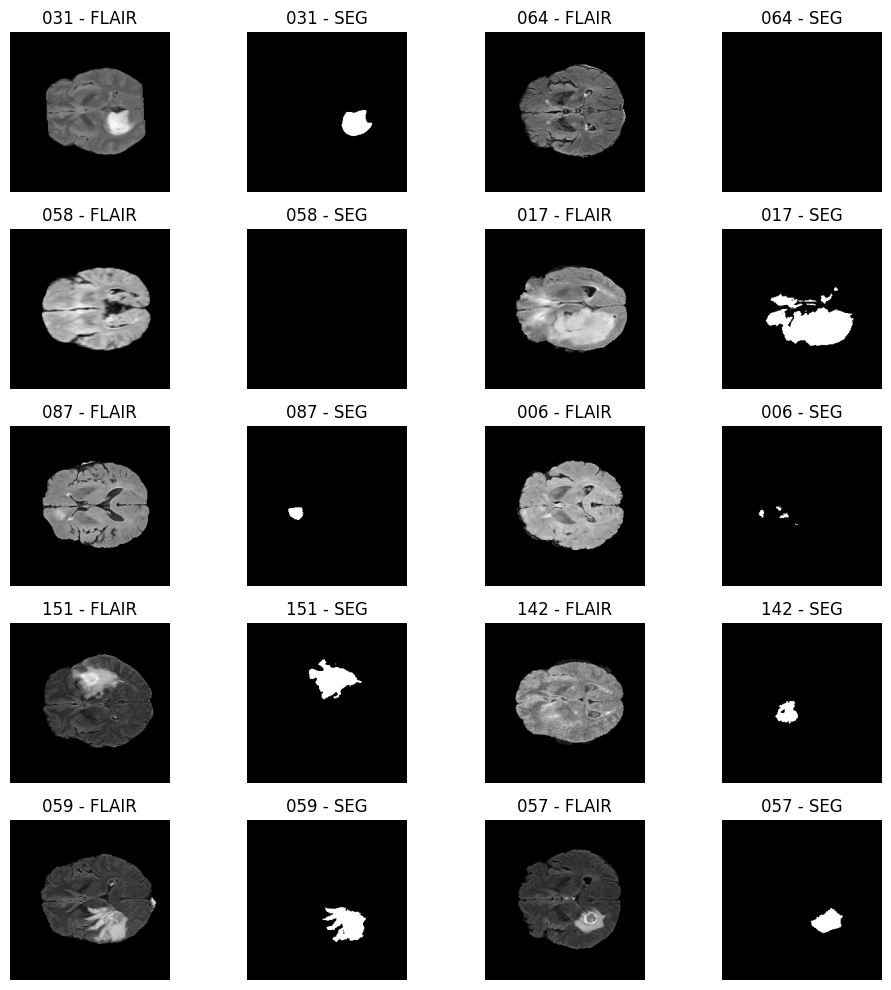

In [ ]:
root_dir = os.path.join(DATA_DIR, "train")

# All the volume folders (001, 002, 003, ...)
sample_dirs = sorted([d for d in os.listdir(root_dir) if not d.startswith('.')])

# 10 random volumes
random_samples = random.sample(sample_dirs, 10)

# 5 rows x 4 columns: two volumes per row, each as FLAIR + mask
fig, axes = plt.subplots(nrows=5, ncols=4, figsize=(10, 10))

for i, sample_id in enumerate(random_samples):
    fla_path = os.path.join(root_dir, sample_id, f"{sample_id}_fla.nii.gz")
    seg_path = os.path.join(root_dir, sample_id, f"{sample_id}_seg.nii.gz")

    img = nib.load(fla_path).get_fdata()
    seg = nib.load(seg_path).get_fdata()

    # Axial slice near the centre of the volume
    slice_idx = 70
    img_slice = img[:, :, slice_idx]
    seg_slice = seg[:, :, slice_idx]

    row = i // 2
    col = (i % 2) * 2  # FLAIR in the even columns, mask in the odd ones

    axes[row, col].imshow(img_slice, cmap='gray')
    axes[row, col].set_title(f"{sample_id} - FLAIR")
    axes[row, col].axis('off')

    axes[row, col + 1].imshow(seg_slice, cmap='gray')
    axes[row, col + 1].set_title(f"{sample_id} - SEG")
    axes[row, col + 1].axis('off')

plt.tight_layout()
plt.show()

Tumours vary a lot in size, shape and position, and some slices contain no tumour at all.
The model has to generalise across all of this.

## 3. Train/validation split and data pipeline

- **Split by volume, not by slice:** 80% of the patients for training (168), 20% for
  validation (42). Slices of the same patient never end up on both sides.
- **2D model on axial slices:** each volume gives 155 slices.
- **Fewer empty slices in training:** a slice with fewer than 10 tumour pixels is dropped
  with probability 0.3, so the model sees more slices that actually contain a tumour.
  Validation keeps every slice.
- **Preprocessing:** z-score normalisation of each slice; the single FLAIR channel is
  repeated on 3 channels; 240 × 240 is padded to 256 × 256 (the U-Net needs a size
  divisible by 32). We first tried resizing, but the interpolation blurred the tumour
  borders, so we switched to padding.
- **Augmentation (training only):** horizontal flip, small shifts, scaling and rotations,
  brightness and contrast changes.

In [ ]:
# Fix the seeds for reproducibility
torch.manual_seed(42)
np.random.seed(42)
random.seed(42)

root_dir = os.path.join(DATA_DIR, "train")

# Folders of the train/validation split
output_dir = os.path.join(OUTPUT_DIR, "split")
train_dir = os.path.join(output_dir, 'Train')
val_dir = os.path.join(output_dir, 'Val')
os.makedirs(train_dir, exist_ok=True)
os.makedirs(val_dir, exist_ok=True)

# All the volume folders ('001', '002', ..., '210')
all_samples = sorted([name for name in os.listdir(root_dir) if not name.startswith('.')])
random.shuffle(all_samples)

# 80% training / 20% validation
split_index = int(0.8 * len(all_samples))
train_samples = all_samples[:split_index]
val_samples = all_samples[split_index:]

print(f"Train: {len(train_samples)} samples")
print(f"Validation: {len(val_samples)} samples")

def copy_samples(sample_list, target_dir):
    for sample_id in sample_list:
        sample_path = os.path.join(root_dir, sample_id)
        fla_file = os.path.join(sample_path, f"{sample_id}_fla.nii.gz")
        seg_file = os.path.join(sample_path, f"{sample_id}_seg.nii.gz")

        # The copied files keep the original volume ID
        shutil.copy(fla_file, os.path.join(target_dir, f"{sample_id}_fla.nii.gz"))
        shutil.copy(seg_file, os.path.join(target_dir, f"{sample_id}_seg.nii.gz"))

copy_samples(train_samples, train_dir)
copy_samples(val_samples, val_dir)

print("Data split and copied.")
print("-"*100)

class BrainSegDataset(Dataset):
    def __init__(self, data_dir, transform=None, augment=False, train=True ):
        """
        data_dir: folder with the volumes, e.g. split/Train or split/Val
        augment: apply the training augmentations
        train: if True, part of the slices without tumour is dropped
        """
        self.train = train
        self.threshold = 10
        self.transform = transform
        self.data_dir = data_dir
        self.sample_ids = sorted(list(set(f.split('_')[0] for f in os.listdir(data_dir) if f.endswith('_fla.nii.gz'))))
        self.augment = augment

        # List of (volume ID, slice index) pairs
        self.slice_info = []  # [(id, z), ...]
        for sample_id in self.sample_ids:
            fla_path = os.path.join(data_dir, f"{sample_id}_fla.nii.gz")
            seg_path = os.path.join(data_dir, f"{sample_id}_seg.nii.gz")
            if not os.path.exists(fla_path):
                continue
            img = nib.load(fla_path).get_fdata()
            seg = nib.load(seg_path).get_fdata()
            num_slices = img.shape[2]

            for z in range(num_slices):
              mask_slice = seg[:, :, z]
              tumor_pixels = np.sum(mask_slice > 0)
              if self.train==True:
                  if tumor_pixels < self.threshold:
                      if random.random() < 0.3:
                          continue  # drop this slice without (almost) any tumour
              self.slice_info.append((sample_id, z))

        # Transforms applied jointly to the image and its mask
        self.base_transform = A.Compose([
          A.PadIfNeeded(min_height=256, min_width=256, border_mode=0),   # 240x240 -> 256x256, zero padding
          ToTensorV2()
        ])

        self.augment_transform = A.Compose([
          A.PadIfNeeded(min_height=256, min_width=256, border_mode=0),
          A.HorizontalFlip(p=0.5),
          A.ShiftScaleRotate(shift_limit=0.05, scale_limit=0.05, rotate_limit=10, p=0.4),
          A.RandomBrightnessContrast(p=0.1, brightness_limit=0.1, contrast_limit=0.1),
          ToTensorV2()
        ])


    def __len__(self):
        return len(self.slice_info)

    def __getitem__(self, idx):
        sample_id, slice_idx = self.slice_info[idx]

        fla_path = os.path.join(self.data_dir, f"{sample_id}_fla.nii.gz")
        seg_path = os.path.join(self.data_dir, f"{sample_id}_seg.nii.gz")

        # Load the NIfTI volumes as numpy arrays
        img = nib.load(fla_path).get_fdata().astype(np.float32)
        seg = nib.load(seg_path).get_fdata().astype(np.uint8)

        # Axial slice
        img_slice = img[:, :, slice_idx]
        seg_slice = seg[:, :, slice_idx]

        # z-score normalization
        img_slice = (img_slice - np.mean(img_slice)) / (np.std(img_slice) + 1e-6)

        # HWC format: the single FLAIR channel is repeated on 3 channels
        img_slice = np.stack([img_slice] * 3, axis=-1)  # (H, W, 3)
        seg_slice = np.expand_dims(seg_slice, axis=-1)  # (H, W, 1)

        # Apply transforms
        if self.augment:
            augmented = self.augment_transform(image=img_slice, mask=seg_slice)
            img_tensor = augmented['image']
            mask_tensor = augmented['mask'].permute(2, 0, 1)

        else:
            augmented = self.base_transform(image=img_slice, mask=seg_slice)
            img_tensor = augmented['image']
            mask_tensor = augmented['mask'].permute(2, 0, 1)

        return img_tensor, mask_tensor

# Create datasets and data loaders
train_dataset = BrainSegDataset(train_dir, augment=True, train=True)
val_dataset = BrainSegDataset(val_dir, augment=False, train=False)

batch_size = 16
train_loader = DataLoader(train_dataset, batch_size=batch_size, shuffle=True, num_workers=0)
val_loader = DataLoader(val_dataset, batch_size=batch_size, shuffle=False, num_workers=0)

print(f'Training batches: {len(train_loader)}')
print(f'Validation batches: {len(val_loader)}')

Train: 168 samples
Validation: 42 samples
Data split and copied.
----------------------------------------------------------------------------------------------------
Training batches: 1346
Validation batches: 407


## 4. Metric

We use the **Dice score**: twice the overlap between the predicted mask and the true mask,
divided by their total size. It goes from 0 (no overlap) to 1 (perfect match), and unlike
pixel accuracy it is not fooled by the background, which covers most of every slice.

During training we add up the true positives, false positives and false negatives over all
the batches of an epoch, and compute one Dice score from the totals.

In [ ]:
def dice_score(preds, targets, epsilon=1e-6):
    # preds and targets both have shape (B, 1, H, W)
    preds = preds.view(-1)
    targets = targets.view(-1)
    intersection = (preds * targets).sum()
    return (2. * intersection + epsilon) / (preds.sum() + targets.sum() + epsilon)


def segmentation_metrics(preds, targets, epsilon=1e-6):
    """
    Count true positives (TP), false positives (FP) and false negatives (FN).
    preds and targets are (B, 1, H, W) tensors of 0s and 1s.
    """
    preds = preds.view(-1)
    targets = targets.view(-1)

    TP = ((preds == 1) & (targets == 1)).sum().float()
    FP = ((preds == 1) & (targets == 0)).sum().float()
    FN = ((preds == 0) & (targets == 1)).sum().float()

    return {
        'TP': TP.item(),
        'FP': FP.item(),
        'FN': FN.item()
    }

## 5. Model: U-Net with a ResNet-18 encoder

- **U-Net:** an encoder that compresses the image and a decoder that rebuilds a full-size
  mask, with skip connections that carry the fine details (the tumour borders) from one to
  the other.
- **ResNet-18 encoder, trained from scratch:** the project did not allow external data or
  pretrained weights. We started with ResNet-50, which overfitted our 168 training volumes
  and converged slowly, so we moved to the smaller ResNet-18.
- **Tversky loss** (α = 0.3, β = 0.7): a generalisation of the Dice loss that penalises
  false negatives more than false positives. Missing part of a tumour is worse than
  flagging a few healthy pixels. With the plain Dice loss the model was less sensitive to
  small tumours.
- **Adam** (learning rate 3·10⁻⁴), halved when the validation Dice does not improve for 3 epochs.

In [ ]:
# U-Net with a ResNet-18 encoder, trained from scratch
model = smp.Unet(
    encoder_name="resnet18",        # encoder
    encoder_weights=None,           # no pretrained weights (not allowed in the project)
    in_channels=3,                  # FLAIR repeated on 3 channels
    classes=1                       # one probability map: tumour / not tumour
)

# Move to the GPU if available
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
model = model.to(device)

print(f'Model created and moved to {device}')
print(f'Total parameters: {sum(p.numel() for p in model.parameters()):,}')
print(f'Trainable parameters: {sum(p.numel() for p in model.parameters() if p.requires_grad):,}')

# Loss on the logits: Tversky, false negatives weigh more than false positives
criterion = TverskyLoss(mode='binary', alpha=0.3, beta=0.7, from_logits=True)

# Optimiser, and learning rate halved when the validation Dice stops improving
optimizer = torch.optim.Adam(model.parameters(), lr=3e-4)
scheduler = ReduceLROnPlateau(optimizer, mode='max', patience=3, factor=0.5)

print("Model configured successfully!")
print(f"Loss function: {criterion}")

Model created and moved to cuda
Total parameters: 14,328,209
Trainable parameters: 14,328,209
Model configured successfully!
Loss function: TverskyLoss()


## 6. Training

20 epochs at most, with early stopping on the validation Dice. A checkpoint is saved after
every epoch so that training can resume when the Colab session disconnects, and the best
model is saved separately.

In [ ]:
def train_epoch(model, train_loader, criterion, optimizer, device):
    model.train()
    epsilon = 1e-6
    running_loss = 0.0
    total_TP, total_FP, total_FN = 0, 0, 0

    with tqdm(total=len(train_loader), desc="Training", unit="batch") as pbar:
        for batch_idx, (data, targets) in enumerate(train_loader):
            data, targets = data.to(device), targets.to(device)

            optimizer.zero_grad()
            outputs = model(data)

            loss = criterion(outputs, targets)
            loss.backward()
            optimizer.step()

            running_loss += loss.item()

            probs = torch.sigmoid(outputs)
            predicted = (probs > 0.5).float()
            targets = targets.float()

            metrics = segmentation_metrics(predicted, targets)
            total_TP += metrics['TP']
            total_FP += metrics['FP']
            total_FN += metrics['FN']

            dice = (2 * total_TP + epsilon) / (2 * total_TP + total_FP + total_FN + epsilon)

            pbar.set_postfix(loss=loss.item(), dice=100 * dice)
            pbar.update(1)

    epoch_loss = running_loss / len(train_loader)
    epoch_dice = 100 * dice
    TP_average = total_TP / len(train_loader)
    FP_average = total_FP / len(train_loader)
    FN_average = total_FN / len(train_loader)

    print(f"\n Train Metrics: "
        f"TP={TP_average:.0f}, FP={FP_average:.0f}, FN={FN_average:.0f}")
    return epoch_loss, epoch_dice


def validate_epoch(model, val_loader, criterion, device):
    epsilon = 1e-6
    model.eval()
    running_loss = 0.0
    total_TP, total_FP, total_FN = 0, 0, 0

    with tqdm(total=len(val_loader), desc="Validating", unit="batch") as pbar:
        with torch.no_grad():
            for batch_idx, (data, targets) in enumerate(val_loader):
                data, targets = data.to(device), targets.to(device)
                outputs = model(data)
                loss = criterion(outputs, targets)

                running_loss += loss.item()

                probs = torch.sigmoid(outputs)
                predicted = (probs > 0.5).float()
                targets = targets.float()

                metrics = segmentation_metrics(predicted, targets)
                total_TP += metrics['TP']
                total_FP += metrics['FP']
                total_FN += metrics['FN']

                dice = (2 * total_TP + epsilon) / (2 * total_TP + total_FP + total_FN + epsilon)

                pbar.set_postfix(loss=loss.item(), dice=100 * dice)
                pbar.update(1)

    epoch_loss = running_loss / len(val_loader)
    epoch_dice = 100 * dice
    TP_average = total_TP / len(val_loader)
    FP_average = total_FP / len(val_loader)
    FN_average = total_FN / len(val_loader)

    print(f"\n Validation Metrics: "
        f"TP={TP_average:.0f}, FP={FP_average:.0f}, FN={FN_average:.0f}")
    return epoch_loss, epoch_dice

#--------------------------------------------------
# Paths
checkpoint_path = os.path.join(OUTPUT_DIR, 'checkpoint.pth')
best_model_path = os.path.join(OUTPUT_DIR, 'best_model.pth')
start_epoch = 0
train_losses, train_dices, val_losses, val_dices = [], [], [], []

# Resume from the checkpoint if there is one
if os.path.exists(checkpoint_path):
    checkpoint = torch.load(checkpoint_path, map_location=device)
    model.load_state_dict(checkpoint['model_state_dict'])
    optimizer.load_state_dict(checkpoint['optimizer_state_dict'])

    if scheduler and checkpoint.get('scheduler_state_dict'):
        scheduler.load_state_dict(checkpoint['scheduler_state_dict'])

    start_epoch = checkpoint['epoch'] + 1
    train_losses = checkpoint.get('train_losses', [])
    train_dices = checkpoint.get('train_dices', [])
    val_losses = checkpoint.get('val_losses', [])
    val_dices = checkpoint.get('val_dices', [])

    print(f" Checkpoint found, resuming training at epoch {start_epoch}")
else:
    print(" No checkpoint, training from scratch")

#---------------------------------------------------------------
# Training loop with early stopping
num_epochs = 20
patience = 10
best_val_dice = 0.0
patience_counter = 0

print("Starting training...")
for epoch in range(start_epoch, num_epochs):
    print(f"Epoch {epoch+1}/{num_epochs}")

    train_loss, train_dice = train_epoch(model, train_loader, criterion, optimizer, device)
    val_loss, val_dice = validate_epoch(model, val_loader, criterion, device)
    scheduler.step(val_dice)

    train_losses.append(train_loss)
    train_dices.append(train_dice)
    val_losses.append(val_loss)
    val_dices.append(val_dice)

    print(f'  Train Loss: {train_loss:.4f}, Train Dice: {train_dice:.2f}%')
    print(f'  Val Loss: {val_loss:.4f}, Val Dice: {val_dice:.2f}%')

    # Save a checkpoint after every epoch
    torch.save({
      'epoch': epoch,
      'model_state_dict': model.state_dict(),
      'optimizer_state_dict': optimizer.state_dict(),
      'scheduler_state_dict': scheduler.state_dict() if scheduler else None,
      'train_losses': train_losses,
      'train_dices': train_dices,
      'val_losses': val_losses,
      'val_dices': val_dices,
    }, checkpoint_path)

    # Keep the best model, stop early if the validation Dice stops improving
    if val_dice > best_val_dice:
        best_val_dice = val_dice
        patience_counter = 0
        torch.save(model.state_dict(), best_model_path)
        print(f'  New best model saved! Val Dice: {best_val_dice:.2f}%')
    else:
        patience_counter += 1
        if patience_counter >= patience:
            print(f'Early stopping triggered after {epoch+1} epochs')
            break

    print('-' * 50)

print(f'Training completed! Best validation Dice: {best_val_dice:.2f}%')

**Result.** The best model reaches a **Dice score of 86.5% on the validation set**
(validation loss 0.144), against 81.9% on the training set (loss 0.193).

## 7. Evaluation on the validation set

We compute the Dice score of the best model over all the validation slices, then plot a few
slices that contain a tumour, with the true mask next to the predicted one.

In [ ]:
# Load the best model
model.load_state_dict(torch.load(best_model_path, map_location=device))
model.to(device)
model.eval()
print(" Loaded best_model.pth")


def evaluate(model, loader, device):
    epsilon = 1e-6
    model.eval()
    running_loss = 0.0
    total_TP, total_FP, total_FN = 0, 0, 0

    with tqdm(total=len(loader), desc="Evaluating", unit="batch") as pbar:
        with torch.no_grad():
            for batch_idx, (data, targets) in enumerate(loader):
                data, targets = data.to(device), targets.to(device)
                outputs = model(data)
                loss = criterion(outputs, targets)
                running_loss += loss.item()

                probs = torch.sigmoid(outputs)
                predicted = (probs > 0.5).float()
                targets = targets.float()

                metrics = segmentation_metrics(predicted, targets)
                total_TP += metrics['TP']
                total_FP += metrics['FP']
                total_FN += metrics['FN']

                dice = (2 * total_TP + epsilon) / (2 * total_TP + total_FP + total_FN + epsilon)
                pbar.set_postfix(loss=loss.item(), dice=100 * dice)
                pbar.update(1)

    epoch_loss = running_loss / len(loader)
    epoch_dice = 100 * dice
    print(f"\n Validation Dice: {epoch_dice:.2f}%, average loss: {epoch_loss:.4f}")
    return epoch_loss, epoch_dice


evaluate(model, val_loader, device)

In [ ]:
def visualize_prediction(model, dataset, device, idx=0, threshold=0.5):
    model.eval()
    img, mask = dataset[idx]
    img = img.to(device).unsqueeze(0)  # add the batch dimension

    with torch.no_grad():
        output = torch.sigmoid(model(img))
        pred_mask = (output > threshold).float()
        mask = mask[0].cpu().numpy()
        pred_mask = pred_mask[0][0].cpu().numpy()

    # Rescale the image to [0, 1] for display
    img = img.squeeze().cpu()
    if img.shape[0] == 3:
        img = img.permute(1, 2, 0).numpy()
        img = (img - img.min()) / (img.max() - img.min() + 1e-8)

    fig, axs = plt.subplots(1, 3, figsize=(12, 4))
    axs[0].imshow(img)
    axs[0].set_title('Image')
    axs[1].imshow(mask, cmap='gray')
    axs[1].set_title('Ground Truth')
    axs[2].imshow(pred_mask, cmap='gray')
    axs[2].set_title(f'Prediction (>{threshold})')
    for ax in axs: ax.axis('off')
    plt.tight_layout()
    plt.show()


# A few validation slices that contain a tumour
with_tumour = [i for i in range(len(val_dataset)) if val_dataset[i][1].sum() > 500]
for idx in random.sample(with_tumour, 3):
    visualize_prediction(model, val_dataset, device, idx)

## 8. Predictions on the test set

The test set (41 volumes) was released at the end of the course, without masks: the
organisers scored the submissions. Each slice goes through the same preprocessing as in
validation, the 8 pixels of padding are removed, and the slices are stacked back into a
240 × 240 × 155 volume saved as NIfTI (`211_fla.nii.gz` → `211_seg.nii.gz`).

In [ ]:
# Load the best model
model.load_state_dict(torch.load(best_model_path, map_location=device))
model.to(device)
model.eval()
print(" Loaded best_model.pth")

# Same preprocessing as in validation: z-score, 3 channels, padding to 256x256
pre_transform = A.Compose([
    A.PadIfNeeded(min_height=256, min_width=256, border_mode=0),
    ToTensorV2()
])

def preprocess(slice_img):
    # z-score normalization
    slice_img = (slice_img - np.mean(slice_img)) / (np.std(slice_img) + 1e-6)
    slice_img = np.stack([slice_img] * 3, axis=-1)  # (H,W,3)
    transformed = pre_transform(image=slice_img)
    return transformed['image']  # (3, H, W)

def predict_volume(model, volume, device):
    model.eval()
    seg_volume = np.zeros((240, 240, volume.shape[2]))

    for i in range(volume.shape[2]):
        slice_img = volume[:, :, i]
        slice_tensor = preprocess(slice_img).unsqueeze(0).to(device)  # (1, 3, H, W)

        with torch.no_grad():
            output = model(slice_tensor)
            pred_mask = (torch.sigmoid(output) > 0.5).float()
            pred_mask = pred_mask[0][0].cpu().numpy()  # (H, W)

        pred_mask = pred_mask[8:-8, 8:-8]   # remove the padding: 256x256 -> 240x240
        seg_volume[:, :, i] = pred_mask

    return seg_volume.astype(np.uint8)

# Predict every test volume and save it as NIfTI
def inference_and_save(model, input_dir, output_dir, device):
    os.makedirs(output_dir, exist_ok=True)

    # One folder per volume (211, 212, ...)
    case_folders = sorted(os.listdir(input_dir))

    for case_folder in tqdm(case_folders, desc="Inference", unit="case"):
        case_path = os.path.join(input_dir, case_folder)
        fla_path = os.path.join(case_path, f"{case_folder}_fla.nii.gz")

        if not os.path.exists(fla_path):
            print(f" {fla_path} not found, skipped")
            continue

        img = nib.load(fla_path)
        volume = img.get_fdata().astype(np.float32)

        seg_volume = predict_volume(model, volume, device)

        # Save as NIfTI, with the same affine as the input scan
        seg_nifti = nib.Nifti1Image(seg_volume, affine=img.affine)
        save_path = os.path.join(output_dir, f"{case_folder}_seg.nii.gz")
        nib.save(seg_nifti, save_path)

    print(f"\n Inference completed, all the results are saved in {output_dir}")

inference_and_save(model, os.path.join(DATA_DIR, "test"), os.path.join(OUTPUT_DIR, "result_final"), device)

Test volume 211, without (left) and with (right) the predicted tumour mask in red, shown in
ITK-SNAP. Sagittal view on top, coronal view below.

![Test volume 211 with the predicted tumour mask](docs/images/test-prediction.png)